<a href="https://colab.research.google.com/github/SnehithG79/Lending-Project-Prediction/blob/main/Loan_Prediction_Status_Changes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub, glob, os

path = kagglehub.dataset_download("wordsforthewise/lending-club")

# Find the accepted file (ignore folders, keep only actual files)
files = []
for f in glob.glob(os.path.join(path, "**", "*accepted*"), recursive=True):
    if os.path.isfile(f):
        files.append(f)

acc_file = files[0]

Using Colab cache for faster access to the 'lending-club' dataset.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

In [3]:


cols = ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade',
        'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
        'issue_d', 'purpose', 'dti', 'delinq_2yrs', 'fico_range_low',
        'fico_range_high', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util',
        'total_acc', 'loan_status']

data = pd.read_csv(acc_file, usecols=cols, low_memory=False)
print(data.shape)
data.head()

(2260701, 22)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,purpose,dti,delinq_2yrs,fico_range_low,fico_range_high,open_acc,pub_rec,revol_bal,revol_util,total_acc
0,3600.0,36 months,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,...,debt_consolidation,5.91,0.0,675.0,679.0,7.0,0.0,2765.0,29.7,13.0
1,24700.0,36 months,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,...,small_business,16.06,1.0,715.0,719.0,22.0,0.0,21470.0,19.2,38.0
2,20000.0,60 months,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,...,home_improvement,10.78,0.0,695.0,699.0,6.0,0.0,7869.0,56.2,18.0
3,35000.0,60 months,14.85,829.90,C,C5,10+ years,MORTGAGE,110000.0,Source Verified,...,debt_consolidation,17.06,0.0,785.0,789.0,13.0,0.0,7802.0,11.6,17.0
4,10400.0,60 months,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,Source Verified,...,major_purchase,25.37,1.0,695.0,699.0,12.0,0.0,21929.0,64.5,35.0


In [4]:
data.shape

(2260701, 22)

In [5]:
data.describe()

,loan_amnt,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,fico_range_high,open_acc,pub_rec,revol_bal,revol_util,total_acc
count,2.260668e+06,2.260668e+06,2.260668e+06,2.260664e+06,2.258957e+06,2.260639e+06,2.260668e+06,2.260668e+06,2.260639e+06,2.260639e+06,2.260668e+06,2.258866e+06,2.260639e+06
mean,1.504693e+04,1.309283e+01,4.458068e+02,7.799243e+04,1.882420e+01,3.068792e-01,6.985882e+02,7.025884e+02,1.161240e+01,1.975278e-01,1.665846e+04,5.033770e+01,2.416255e+01
std,9.190245e+03,4.832138e+00,2.671735e+02,1.126962e+05,1.418333e+01,8.672303e-01,3.301038e+01,3.301124e+01,5.640861e+00,5.705150e-01,2.294831e+04,2.471307e+01,1.198753e+01
min,5.000000e+02,5.310000e+00,4.930000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,6.100000e+02,6.140000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
25%,8.000000e+03,9.490000e+00,2.516500e+02,4.600000e+04,1.189000e+01,0.000000e+00,6.750000e+02,6.790000e+02,8.000000e+00,0.000000e+00,5.950000e+03,3.150000e+01,1.500000e+01
50%,1.290000e+04,1.262000e+01,3.779900e+02,6.500000e+04,1.784000e+01,0.000000e+00,6.900000e+02,6.940000e+02,1.100000e+01,0.000000e+00,1.132400e+04,5.030000e+01,2.200000e+01
75%,2.000000e+04,1.599000e+01,5.933200e+02,9.300000e+04,2.449000e+01,0.000000e+00,7.150000e+02,7.190000e+02,1.400000e+01,0.000000e+00,2.024600e+04,6.940000e+01,3.100000e+01
max,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,9.990000e+02,5.800000e+01,8.450000e+02,8.500000e+02,1.010000e+02,8.600000e+01,2.904836e+06,8.923000e+02,1.760000e+02


In [6]:
data.isnull().sum()

,0
loan_amnt,33
term,33
int_rate,33
installment,33
grade,33
sub_grade,33
emp_length,146940
home_ownership,33
annual_inc,37
verification_status,33


In [7]:
def drop_rows(data):
  cols = ["delinq_2yrs", "open_acc", "pub_rec", "total_acc", "loan_status"]
  data = data.dropna(subset=cols)
  data = data.drop(columns="emp_length")
  return data

data = drop_rows(data)


In [8]:
data['fico'] = data['fico_range_high'] + data['fico_range_low'] / 2
data = data.drop(columns=["fico_range_high","fico_range_low"])
# Combining the Fiscal Range Score so implementation becomes easier

In [9]:
data[["revol_util","dti"]].head()

,revol_util,dti
0,29.7,5.91
1,19.2,16.06
2,56.2,10.78
3,11.6,17.06
4,64.5,25.37


In [10]:
data['loan_status'].value_counts()

,count
loan_status,
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1962
Does not meet the credit policy. Status:Charged Off,758
Default,40


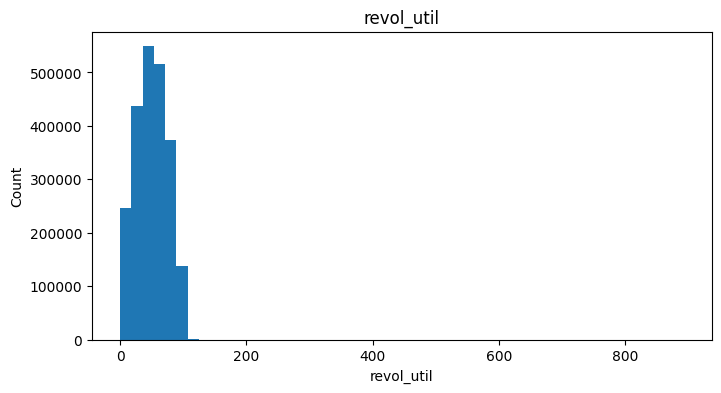

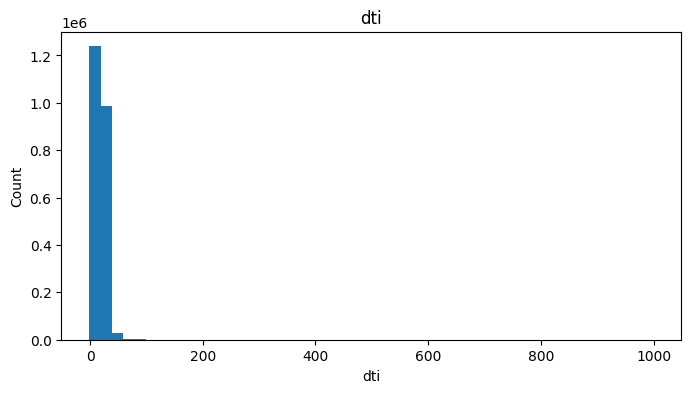

In [11]:
def plot(data):
    columns = ["revol_util", "dti"]
    for col in columns:
        plt.figure(figsize=(8, 4))
        plt.hist(data[col].dropna(), bins=50)
        plt.title(col)
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.show()

plot(data)

# Dropna is necessary to handle missing values

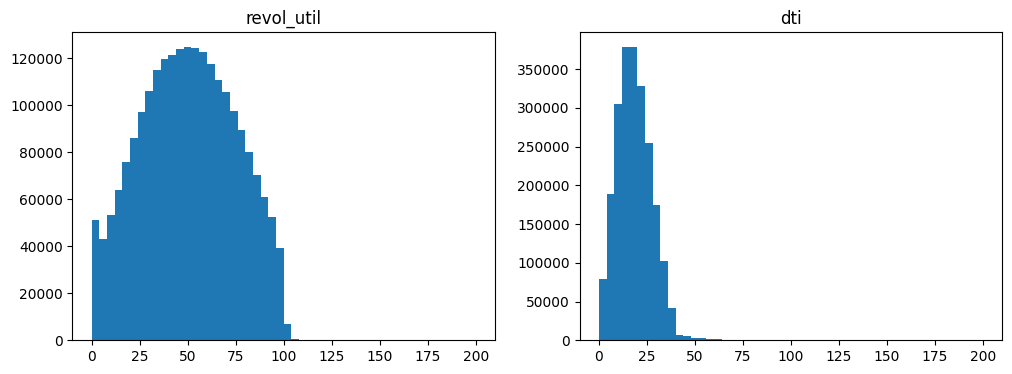

In [12]:
fig, axes = plt.subplots(1,2, figsize=(12, 4))
for ax, col in zip(axes,["revol_util", "dti"]):
    ax.hist(data[col].dropna(), bins=50,range=(0,200))
    ax.set_title(col)
plt.show()



In [13]:
def fill_column(data):
  columns = ["revol_util", "dti"]
  for col in columns:
    data[col] = data[col].fillna(data[col].median())
  return data

data = fill_column(data)


In [14]:
status_map = {
    "Fully Paid": 0,
    "Does not meet the credit policy. Status:Fully Paid": 0,
    "Charged Off": 1,
    "Does not meet the credit policy. Status:Charged Off": 1,
    "Default": 1,
}

# Map statuses to 0/1; Current, Late and Grace Period become NaN
data["default"] = data["loan_status"].map(status_map)

# Drop loans with no final outcome (also removes the missing loan_status rows)
data = data.dropna(subset=["default"]).copy()
data["default"] = data["default"].astype(int)

# Check the result
print(data["default"].value_counts())
print(data["default"].value_counts(normalize=True))
print(len(data))

default
0    1078713
1     269357
Name: count, dtype: int64
default
0    0.800191
1    0.199809
Name: proportion, dtype: float64
1348070


In [15]:
def encode_columns(data):
    data = data.copy()
    data["term"] = data["term"].str.extract(r"(\d+)").astype(int)
    data["grade"] = data["grade"].astype("category").cat.codes
    data["sub_grade"] = data["sub_grade"].astype("category").cat.codes
    return pd.get_dummies(data, columns=["home_ownership", "verification_status", "purpose"], dtype=int)

data = encode_columns(data)

In [16]:
import numpy as np
import time
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             roc_auc_score, average_precision_score, recall_score)
from xgboost import XGBClassifier
import seaborn as sns
import matplotlib.pyplot as plt


def Machine_Model(data, fn_cost=3, fp_cost=1):
    start = time.time()

    X = data.drop(["loan_status", "default", "issue_d"], axis=1)
    Y = data["default"]

    # 1. Split: 80% train / 20% test, then hold out 10% of train as validation
    X_train, X_test, Y_train, Y_test = train_test_split(
        X, Y, test_size=0.2, random_state=2, stratify=Y)
    X_tr, X_val, Y_tr, Y_val = train_test_split(
        X_train, Y_train, test_size=0.1, random_state=2, stratify=Y_train)

    # 2. Class weight: ~4 repaid loans per default
    ratio = (Y_tr == 0).sum() / (Y_tr == 1).sum()
    print(f"scale_pos_weight = {ratio:.2f}")

    # No StandardScaler: tree models don't need scaling
    model = XGBClassifier(
        device="cuda",            # T4 GPU
        tree_method="hist",
        eval_metric="aucpr",
        scale_pos_weight=ratio,
        random_state=2,
    )

    # 3. Bigger search space
    param_distributions = {
        "max_depth": [4, 6, 8],
        "learning_rate": [0.03, 0.05, 0.1],
        "n_estimators": [300, 600, 1000],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.7, 0.8, 1.0],
        "min_child_weight": [1, 5, 10],
    }

    # 4. Score on average precision (rewards ranking defaults well)
    search = RandomizedSearchCV(
        model, param_distributions, n_iter=15,
        scoring="average_precision",
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=2),
        random_state=2,
        n_jobs=1,                 # 1 job: parallel jobs would fight over one GPU
        verbose=1,
    )
    search.fit(X_tr, Y_tr)
    print("Best Params:", search.best_params_)

    # 5. Refit the best model with early stopping on the validation set
    best = XGBClassifier(
        **{**search.best_params_, "n_estimators": 3000},
        device="cuda", tree_method="hist", eval_metric="aucpr",
        scale_pos_weight=ratio, early_stopping_rounds=50, random_state=2,
    )
    best.fit(X_tr, Y_tr, eval_set=[(X_val, Y_val)], verbose=False)
    print("Trees used after early stopping:", best.best_iteration + 1)

    # 6. Choose the threshold on VALIDATION by minimising cost
    #    (a missed default costs fn_cost x a false alarm)
    val_proba = best.predict_proba(X_val)[:, 1]
    thresholds = np.arange(0.05, 0.95, 0.01)
    def cost(y, p, t):
        pred = (p >= t).astype(int)
        fn = ((pred == 0) & (y == 1)).sum()
        fp = ((pred == 1) & (y == 0)).sum()
        return fn_cost * fn + fp_cost * fp
    costs = [cost(Y_val.values, val_proba, t) for t in thresholds]
    best_t = thresholds[int(np.argmin(costs))]
    print(f"Chosen threshold: {best_t:.2f}")

    # 7. Final evaluation on the untouched TEST set
    test_proba = best.predict_proba(X_test)[:, 1]
    pred_default = (test_proba >= 0.5).astype(int)
    pred_tuned = (test_proba >= best_t).astype(int)

    print("\n=== Threshold 0.5 ===")
    print(classification_report(Y_test, pred_default))
    print(f"\n=== Tuned threshold {best_t:.2f} ===")
    print(classification_report(Y_test, pred_tuned))

    cost_default = cost(Y_test.values, test_proba, 0.5)
    cost_tuned = cost(Y_test.values, test_proba, best_t)

    results = {
        "ROC-AUC": roc_auc_score(Y_test, test_proba),
        "PR-AUC": average_precision_score(Y_test, test_proba),
        "Recall @0.5": recall_score(Y_test, pred_default),
        "Recall @tuned": recall_score(Y_test, pred_tuned),
        "Accuracy @tuned": accuracy_score(Y_test, pred_tuned),
        "Cost reduction %": 100 * (cost_default - cost_tuned) / cost_default,
    }
    for k, v in results.items():
        print(f"{k}: {v:.3f}")

    sns.heatmap(confusion_matrix(Y_test, pred_tuned), annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.title(f"Confusion matrix (threshold {best_t:.2f})")
    plt.show()

    print(f"\nTotal time: {(time.time() - start) / 60:.1f} min")
    return best, best_t, results


scale_pos_weight = 4.00
Fitting 3 folds for each of 15 candidates, totalling 45 fits


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [20:20:23] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Best Params: {'subsample': 1.0, 'n_estimators': 600, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Trees used after early stopping: 800
Chosen threshold: 0.57

=== Threshold 0.5 ===
              precision    recall  f1-score   support

           0       0.89      0.65      0.75    215743
           1       0.32      0.66      0.44     53871

    accuracy                           0.66    269614
   macro avg       0.61      0.66      0.59    269614
weighted avg       0.77      0.66      0.69    269614


=== Tuned threshold 0.57 ===
              precision    recall  f1-score   support

           0       0.87      0.77      0.82    215743
           1       0.37      0.53      0.43     53871

    accuracy                           0.72    269614
   macro avg       0.62      0.65      0.62    269614
weighted avg       0.77      0.72      0.74    269614

ROC-AUC: 0.720
PR-AUC: 0.391
Recall @0.5: 0.664
Recall @tuned: 0.525
Accuracy @tuned: 0.723


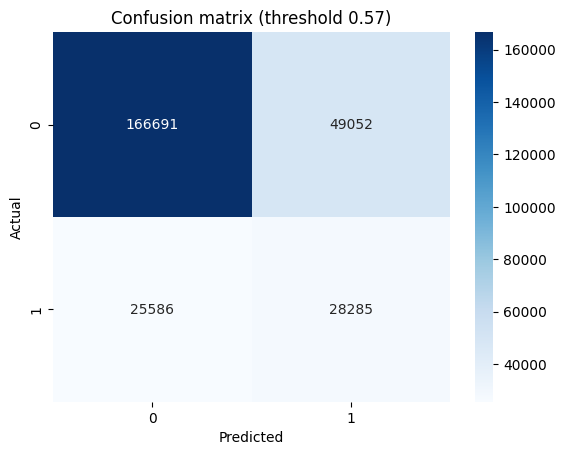


Total time: 5.2 min


(XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.7, device='cuda', early_stopping_rounds=50,
               enable_categorical=True, eval_metric='aucpr', feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=0.03, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
               max_leaves=None, min_child_weight=10, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=3000,
               n_jobs=None, num_parallel_tree=None, ...),
 np.float64(0.5700000000000002),
 {'ROC-AUC': np.float64(0.7197321080139008),
  'PR-AUC': np.float64(0.3910421823631562),
  'Recall @0.5': 0.6638079857437211,
  'Recall @tuned': 0.5250505838020456,
  'Accuracy @tuned': 0.7231671945

In [17]:
Machine_Model(data)